We want to solve the following equation numerically:
$$
\frac{d^{2}\psi(x)}{dx^{2}} + k^{2}\psi(x) = 0
$$
where $k^{2} = 2m\left[E-V(x)\right]/\hbar^{2}$. <br>
We divide the $x$-axis into a set of equidistant points with a spacing of $h_{0}=\Delta x$. The wavefunction can be approximately described by its values at the points of the grid. <br>
The first derivative is approximated as:
$$
\frac{d\psi}{dx} = \frac{\psi_{n+1}-\psi_{n}}{h_{0}}
$$
The *second derivative* is a bit *tricky* to calculate. We, however, use the *Numerov Algorithm* to compute it. Without going into further details, the iterative formula for the wavefunction is directly given as:
$$
\psi_{n+1} = \frac{2\left(1-\frac{5}{12}h_{0}^{2}k_{n}^{2}\right)\psi_{n}-\left(1+\frac{1}{12}h_{0}^{2}k_{n-1}^{2}\right)\psi_{n-1}}{1+\frac{1}{12}h_{0}^{2}k_{n+1}^{2}}
$$

**ALGORITHM :**

$\bullet$ Choose Initial Conditions <br>
For bound-state problems, choose small non-zero values at the first two points:
$$
\psi_0 = 0, \quad \psi_1 = \epsilon \quad (\text{e.g., } \epsilon = 10^{-6})
$$

$\bullet$ Apply the Numerov integration formula (to be used to calculate the numerical values of the wavefunction too)

$\bullet$ To find correct energy:

1. Start with a guess $E_{0}$ for the energy.
2. Integrate $\psi(x)$ across the domain.
3. Check boundary conditions (e.g., $\psi(x_{\text{max}})$ $\approx 0$).
4. Adjust $E$ until the boundary condition is satisfied within desired tolerance.

___

#### 1. NUMERICAL SOLUTION OF THE TISE FOR A LINEAR HARMONIC OSCILLATOR

n	E_n [MeV] (Calculated)	   E_n [MeV] (Exact)	    Error %
0	1.7574241672644362	   1.757425925058921	    0.00010002097156948321
1	5.272276015594302	   5.272277775176763	    3.337423664121052e-05
2	8.78712786061739	   8.787129625294606	    2.0082521713822204e-05
3	12.3019797000943	   12.301981475412447	    1.4431156072386409e-05
4	15.816831535368205	   15.81683332553029	    1.1318081486373878e-05


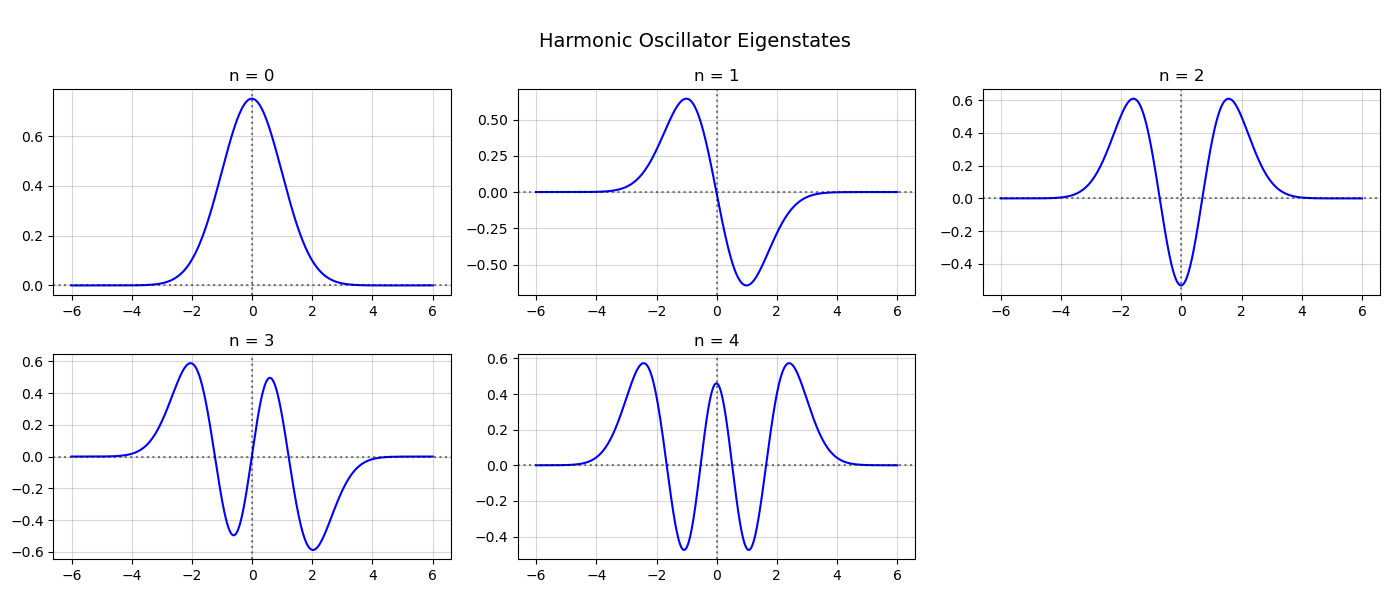

In [1]:
import numpy as np
from scipy.constants import hbar,e
import matplotlib.pyplot as plt

# Defining some runtime/numerical constants
epsilon = 1e-10 # precision for energy refinement
no_divisions = 1000
N_max = 5 # number of eigenstates to compute
xRange = 12
h_0 = xRange/no_divisions

x_grid = np.linspace(-0.5*xRange,0.5*xRange,no_divisions+1)

E_pot = 0.5*(x_grid**2)

# Defining the boundary conditions
Psi_left = 1e-3
Psi_right = 0

# Storage arrays for wavefunctions and eigen-energies
wavefunctions = np.zeros((N_max,no_divisions+1))
eigen_energies = np.zeros(N_max)

# Initial wavefunction array
Psi = np.zeros(no_divisions+1)
Psi[0] = Psi_left
Psi[1] = Psi_left+1e-3

# Defining the initial energy brackets
E_lower = 0
E_upper = 10

End_sign = -1 # To flip sign at right boundary for successive eigenstates (for even/odd parity)

# Main looping over each eigenstate
for i in range(1,N_max+1):

    # Finding an energy bracket that produces exactly i nodes
    Limits_are_defined = False

    while not Limits_are_defined:
        nodes_p = 0
        E_trial = E_upper
        # Integrating once with this trial energy
        Psi_local = np.empty_like(Psi)
        Psi_local[0] = Psi[0]
        Psi_local[1] = Psi[1]

        K_square = 2*(E_trial-E_pot)
        
        # Numerov integration and node counting
        for j in range(2,no_divisions+1):

            # Numerov formula implementation
            denom = 1+(((h_0**2)*K_square[j])/12)
            numer = (2*Psi_local[j-1]*(1-((5*(h_0**2)* K_square[j])/12)))-((1+((1/12)*((h_0**2)*K_square[j-1])))*Psi_local[j-2])
            Psi_local[j] = numer/denom

            # Counting nodes
            if (Psi_local[j]*Psi_local[j-1]<0):
                nodes_p += 1

        # Adjusting energy limits according to node count
        if (E_upper<E_lower):
            E_upper = max(2*E_upper,-2*E_upper)
        if (nodes_p>i):
            E_upper *= 0.7
        elif (nodes_p<i):
            E_upper *= 2
        else:
            Limits_are_defined = True

    # Refining the energy bracket by bisection method
    End_sign = -End_sign

    while (E_upper-E_lower)>epsilon:
        # Numerov integration with the new energy bracket
        E_trial = 0.5*(E_upper+E_lower)
        Psi_local[0] = Psi[0]
        Psi_local[1] = Psi[1]
        K_square = 2*(E_trial-E_pot)
        for k in range(2,no_divisions+1):
            denom = 1+(((h_0**2)*K_square[k])/12)
            numer = (2*Psi_local[k-1]*(1-((5*(h_0**2)*K_square[k])/12)))-((1+((1/12)*((h_0**2)*K_square[k-1])))*Psi_local[k-2])
            Psi_local[k] = numer/denom
        # Assigning the correct energy values
        if ((End_sign*Psi_local[-1])>Psi_right):
            E_lower = E_trial
        else:
            E_upper = E_trial

    # Storing the correct energy eigenvalues
    E_trial = 0.5*(E_upper+E_lower)
    eigen_energies[i-1] = E_trial
    E_upper = E_trial
    E_lower = E_trial

    # Computing normalisation and eigenfunction values
    Psi_local[0] = Psi[0]
    Psi_local[1] = Psi[1]
    # Numerov integration to calculate wavefunction values with correct eigen-energy
    K_square = 2*(E_trial-E_pot)
    for l in range(2,no_divisions+1):
        denom = 1.0 + (h_0 * h_0 * K_square[l] / 12.0)
        numer = (2*Psi_local[l-1]*(1-((5*(h_0**2)*K_square[l])/12)))-((1+((1/12)*((h_0**2)*K_square[l-1])))*Psi_local[l-2])
        Psi_local[l] = numer/denom
        
    # Normalization using trapezoidal-like numerical integration
    Integral = 0
    for m in range(1,no_divisions+1):
        Integral += 0.5*h_0*((Psi_local[m-1]*Psi_local[m-1])+(Psi_local[m]*Psi_local[m]))
    Normalization_coefficient = np.sqrt(1.0 / Integral)
    wavefunctions[i-1,:] = Normalization_coefficient*Psi_local

# Calculating LHO energy and comparing with actual values
def lho_energy(n):
    return (n+0.5)
omega = 5.34e21 # per second
Energyscale = (hbar*omega)/(e*1e6)
energies_MeV = Energyscale*eigen_energies
exact_energy = [Energyscale*lho_energy(i) for i in range(0,5)]
# Printing results
print("n\tE_n [MeV] (Calculated)\t   E_n [MeV] (Exact)\t    Error %")
print("===================================================================================")
for i,E in enumerate(energies_MeV):
    print(f"{i}\t{E}\t   {exact_energy[i]}\t    {(abs(E-exact_energy[i])/exact_energy[i])*100}")

# Plotting the wavefunctions
N = wavefunctions.shape[0]
fig, axes = plt.subplots(2,3,figsize=(14,6))
axes = axes.flatten()
for n in range(6):
    ax = axes[n]
    if n < N:
        ax.plot(x_grid,wavefunctions[n],color='b')
        ax.axhline(color='black',alpha=0.5,linestyle='dotted')
        ax.axvline(color='black',alpha=0.5,linestyle='dotted')
        ax.set_title(f"n = {n}")
        ax.grid(alpha=0.5)
    else:
        ax.axis("off")
fig.suptitle("\nHarmonic Oscillator Eigenstates",fontsize=14)
plt.tight_layout()
plt.show()

#### 2. TESTING FOR A SIMPLE PARTICLE IN A 1D INFINITE POTENTIAL WELL

n	E_num			E_exact			Error %
1	4.934802200587001	4.934802200544679	8.576169819742666e-10
2	19.739208802056964	19.739208802178716	6.16800293226823e-10
3	44.413219803645916	44.41321980490211	2.8284302056412915e-09
4	78.95683520036982	78.95683520871486	1.0569116900834176e-08
5	123.37005498238796	123.37005501361698	2.531329109270569e-08


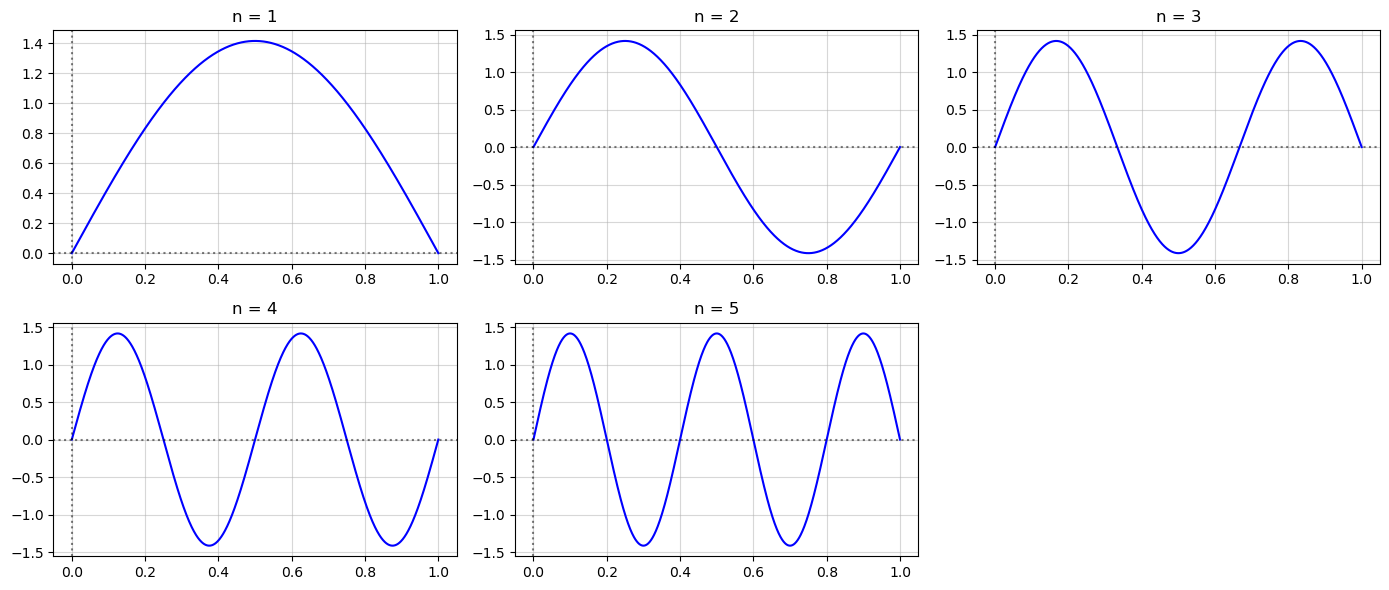

In [2]:
# here hbar=m=1

import numpy as np
import matplotlib.pyplot as plt

# Defining some runtime/numerical constants
N_max = 5 # Number of eigenstates
N_points = 1001 # Number of grid points for numerical calculation
a = 1 # Width of the potential well
h = a/(N_points-1) 
x = np.linspace(0,a,N_points)
V = np.zeros_like(x) # Defining the square well potential
psi0 = 0
psi1 = 1e-6
epsilon = 1e-9 

# Creating storage arrays for wavefunction and energy
energies = np.zeros(N_max)
wavefunctions = np.zeros((N_max,N_points)) # To store wavefunctions

# Function to implement Numerov integration
def numerov(E,V,h,psi0,psi1):
    N = len(V)
    
    psi = np.zeros(N)
    psi[0] = psi0
    psi[1] = psi1
    
    K2 = 2*(E-V)
    
    for i in range(1, N-1):
        f1 = 1+((h**2)*(K2[i-1]/12))
        f2 = 2*(1-(5*(h**2)*(K2[i]/12)))
        f3 = 1+((h**2)*(K2[i+1]/12))
        psi[i+1] = ((f2*psi[i]) - (f1*psi[i-1]))/f3
    
    return (psi)

# Looping over all quantum states to find eigen-energies and wavefunctions
for n in range(1, N_max+1):
    target_nodes = n-1  # Each quantum state has n-1 nodes

    # Defining energy bracket for bisection
    E_low = 0
    E_high = (n**2)*5

    while ((E_high-E_low)>epsilon):
        E_trial = 0.5*(E_low+E_high)
        psi = numerov(E_trial,V,h,psi0,psi1)
        nodes = np.sum(psi[:-1]*psi[1:]<0)  # Counting zero-crossings/nodes

        if (nodes>target_nodes):
            E_high = E_trial
        else:
            E_low = E_trial

    E_found = 0.5*(E_low+E_high)
    energies[n-1] = E_found
    # Storin normalized wavefunction
    psi_final = numerov(E_found,V,h,psi0,psi1)
    psi_final /= np.sqrt(np.trapezoid(psi_final**2,x))  # Normalizing
    wavefunctions[n-1,:] = psi_final

# Calculating energies and comparing
E_exact = ((np.arange(1,N_max+1)**2)*(np.pi**2))/(2*(a**2))
print("n\tE_num\t\t\tE_exact\t\t\tError %")
print("===============================================================================")
for i in range(N_max):
    print(f"{i+1}\t{energies[i]}\t{E_exact[i]}\t{(abs(energies[i]-E_exact[i])/E_exact[i])*100}")

# Plotting the wavefunctions
fig, axes = plt.subplots(2,3,figsize=(14,6))
axes = axes.flatten()
for n in range(N_max):
    axes[n].plot(x,wavefunctions[n,:],color='b')
    axes[n].set_title(f"n = {n+1}")
    axes[n].axhline(color='black',alpha=0.5,linestyle='dotted')
    axes[n].axvline(color='black',alpha=0.5,linestyle='dotted')
    axes[n].grid(alpha=0.5)
for i in range(N_max,6):
    axes[i].axis('off')
plt.tight_layout()
plt.show()

#### 3. A PARTICLE IN AN ATTRACTIVE DELTA POTENTIAL $V(x) = -V_{0}\delta(x)$

Bound Energy (Numerical) = -0.4839590372691873
Bound Energy (Exact) = -0.5
Error ≈ 3.208 %


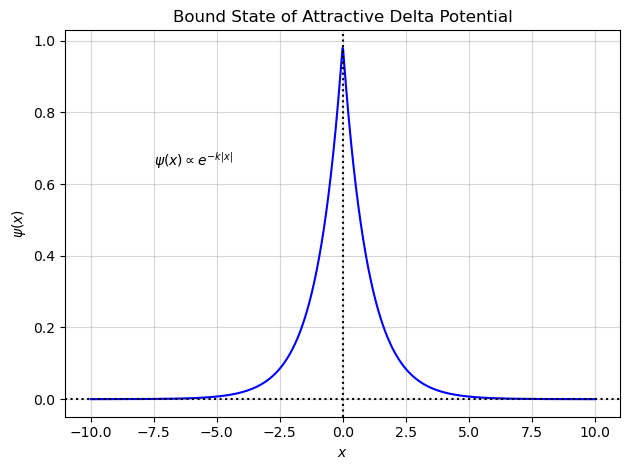

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Defining the runtime/numerical constants
epsilon = 1e-9
no_divisions = 10000
xRange = 20
h = xRange/no_divisions
x_grid = np.linspace(-0.5*xRange,0.5*xRange,no_divisions+1)

# Defining the delta potential
V0 = 1
a_delta = 0.05 # Numerical width of delta function
V = np.zeros_like(x_grid)
mask = np.abs(x_grid)<(a_delta/2)
V[mask] = -V0/a_delta

# Defining the initial wavefunction and energy bracket values 
Psi_left = 1e-3
Psi = np.zeros(no_divisions+1)
Psi[0] = Psi_left
Psi[1] = Psi_left+1e-3
E_lower = -2.0
E_upper = -1e-6

# Numerov algorithm implementation function
def numerov(E):
    Psi_local = np.zeros_like(Psi)
    Psi_local[0] = Psi[0]
    Psi_local[1] = Psi[1]
    k2 = 2*(E-V)
    for i in range(2,no_divisions+1):
        denom = 1+((h**2)*k2[i])/12
        numer = (2*Psi_local[i-1]*(1-(5*(h**2)*k2[i-1])/12))-(Psi_local[i-2]*(1+((h**2)*k2[i-2])/12))
        Psi_local[i] = numer/denom

    return (Psi_local)

# Finding correct energy bracket by bisection
while (E_upper - E_lower) > epsilon:
    E_mid = 0.5*(E_upper+E_lower)
    Psi_mid = numerov(E_mid)
    if (Psi_mid[-1]>0):
        E_lower = E_mid
    else:
        E_upper = E_mid

# Calculating true bound energy and wavefunction values
E_bound = 0.5*(E_upper+E_lower)
Psi_bound = numerov(E_bound)
# Normalizing the wavefunction
norm = np.sqrt(np.trapezoid(Psi_bound**2,x_grid))
Psi_bound /= norm

# Calculating exact energy
E_exact = -0.5*(V0**2)

# Printing the results
print(f"Bound Energy (Numerical) = {E_bound}")
print(f"Bound Energy (Exact) = {E_exact}")
print(f"Error ≈ {round((abs(E_bound-E_exact)/abs(E_exact))*100,3)} %")

# Plotting the bound state eigenfunction
plt.figure()
plt.plot(x_grid,Psi_bound,color='b')
plt.axvline(0,color="black",linestyle="dotted")
plt.axhline(0,color="black",linestyle="dotted")
plt.title("Bound State of Attractive Delta Potential")
plt.xlabel("$x$")
plt.text(-7.5,0.65,"$\\psi(x)\\propto e^{-k|x|}$")
plt.ylabel("$\\psi(x)$")
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()